# Dynamics

Woher Bewegungsgleichungen kommen, wie man sie löst und wann sie unvorhersagbar werden, durchgerechnet mit numpy, scipy und sympy: die Variationsrechnung mit Brachistochrone, direkter Methode, Noether und Geodäten; Differentialgleichungen von exakten Lösungen über Integratoren, steife Gleichungen, Wärme-, Wellen- und Schrödinger-Gleichung bis zur Floquet-Theorie; und das Chaos mit Pendel, logistischer Abbildung, Lorenz-System, Lyapunov-Exponenten und fraktaler Dimension. Daten werden nicht geladen. Der Code steht in [`code/dynamics/`](https://github.com/deltorobarba/science/tree/main/code/dynamics), ein Modul je Teil (`variations.py`, `odes.py`, `nonlinear.py`); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die drei Teile folgen einer Bewegungsgleichung durch ihr Leben: woher sie kommt, wie man sie löst und wann ihre Lösung unvorhersagbar wird.

- **Schritte 1 bis 5, Variationsrechnung:** Die Natur wählt Bahnen, die eine Größe extremal machen. Daraus folgen die Euler-Lagrange-Gleichungen, und aus Symmetrien die Erhaltungsgrößen (Noether).
- **Schritte 6 bis 15, Differentialgleichungen:** Exakte Lösungen sind selten; numerische Verfahren haben eine Ordnung, erhalten die Energie oder nicht und werden ab einer Schrittweite instabil (steif, CFL).
- **Schritte 16 bis 21, Chaos:** Auch einfache deterministische Gleichungen können kleine Fehler exponentiell verstärken; Lyapunov-Exponenten messen wie schnell, die fraktale Dimension die Gestalt des Attraktors.

Die gemeinsame Lehre: Stabilität entscheidet alles, für die Bahn wie für das Verfahren. Eigenwerte sagen, ob eine Störung wächst, ob ein Integrator explodiert und ob ein System chaotisch ist.

In [1]:
import sys
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "dynamics"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["variations.py", "odes.py", "nonlinear.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/dynamics/{f}", CODE / f)
if "google.colab" not in sys.modules and (importlib.util.find_spec("sympy") is None):
    raise ImportError("Es fehlt eines der Pakete sympy; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import variations, odes, nonlinear

**1. Variationsrechnung: Werkzeuge**

Die gewöhnliche Analysis sucht den Punkt, an dem eine Funktion am kleinsten ist; die Variationsrechnung sucht die Funktion, an der eine Größe am kleinsten ist, die von der ganzen Funktion abhängt: die Kurve mit der kürzesten Laufzeit, die kürzeste Verbindung auf einer gekrümmten Fläche, die Bahn mit der kleinsten Wirkung. Die Bedingung dafür ist eine Differentialgleichung, die Euler-Lagrange-Gleichung; so entstehen die Bewegungsgleichungen der Physik. Am Anfang stand 1696 Johann Bernoullis Frage nach der Brachistochrone, der Bahn des schnellsten Falls.

Bereitgestellt werden die Laufzeit entlang eines Polygonzugs und die Zykloide durch den Endpunkt: Sie ist durch a = 0.2586 m festgelegt und braucht T = 0.5696 s.

In [2]:
variations.load()

Zykloide: a = 0.2586 m, theta1 = 3.5084 (tiefster Punkt bei theta = pi), T = 0.5696 s


**2. Laufzeiten verschiedener Bahnen**

Ein Körper gleitet ohne Reibung von (0, 0) nach (1, 0.5). Verglichen werden die Gerade, Potenzkurven und die Zykloide.

Die Gerade ist der kürzeste Weg, braucht aber 0.714 s. Die Zykloide fällt am Anfang am steilsten, taucht sogar etwas unter das Ziel und braucht nur 0.570 s: Steil am Anfang lohnt sich, weil der Körper früh schnell wird. Die beste Potenzkurve (Exponent 0.38) bleibt mit 0.58 s darüber.

Kontrolle: Gerade numerisch 0.71392 s, exakt 0.71392 s
Kontrolle: Zykloide numerisch 0.56962 s, exakt 0.56962 s


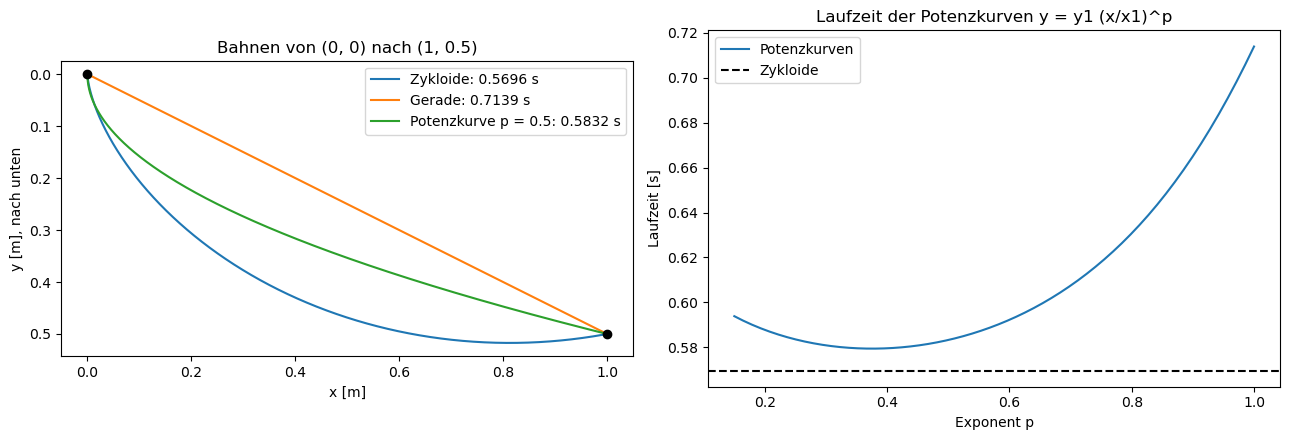

In [3]:
variations.travel_times()

**3. Die direkte Methode**

Statt die Euler-Lagrange-Gleichung zu lösen, wird die Laufzeit direkt minimiert: Die Unbekannten sind die Höhen eines Polygonzugs an festen Stellen, gestartet wird mit der Geraden.

Der gefundene Polygonzug liegt auf der ganzen Länge auf der Zykloide, auch dort, wo sie unter das Ziel taucht. Seine Laufzeit (0.56964 s) ist minimal größer als die der Zykloide (0.56962 s), weil er die Kurve nur mit 81 geraden Stücken nachbildet.

Minimierung: T = 0.56964 s nach 165 Schritten, Zykloide exakt 0.56962 s


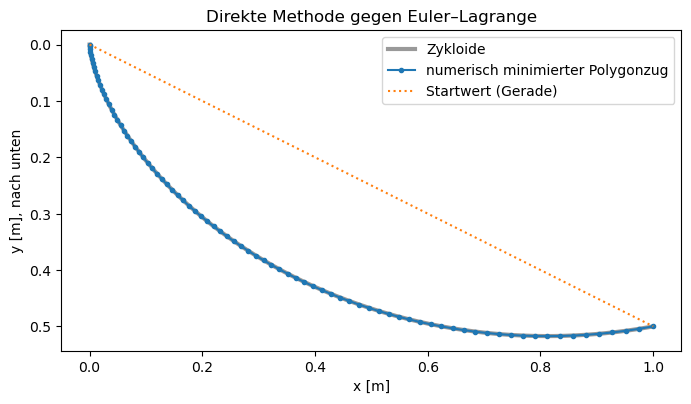

In [4]:
variations.direct_method()

**4. Noether am Zentralkraftproblem**

Nach Emmy Noether gehört zu jeder Symmetrie eine Erhaltungsgröße: zur Zeitverschiebung die Energie, zur Drehung der Drehimpuls. Eine Bahn wird mit einem Zentralpotential und mit einer kleinen Störung integriert, die die Drehsymmetrie bricht.

Die Energie bleibt in beiden Fällen erhalten, bis auf 4·10⁻¹⁰, weil kein Potential von der Zeit abhängt. Der Drehimpuls ist nur ohne Störung erhalten; mit Störung schwankt er, und die Ellipse dreht sich von Umlauf zu Umlauf weiter.

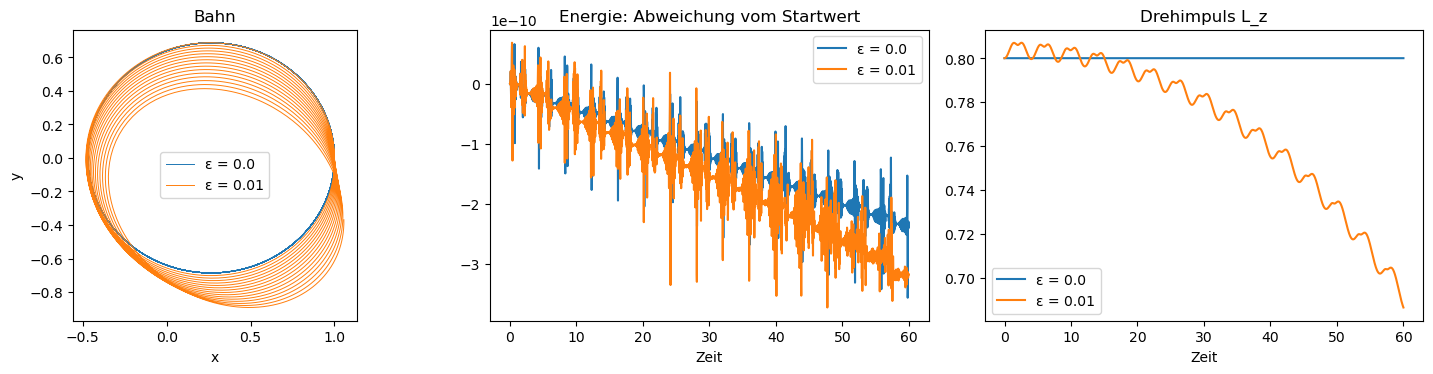

In [5]:
variations.noether()

**5. Geodäten auf der Kugel**

Die kürzeste Verbindung auf der Kugel ist ein Großkreis. Die Geodätengleichungen werden integriert; wegen der Drehsymmetrie um die Achse bleibt die Clairaut-Größe erhalten.

Die Geodäte ist ein geneigter Großkreis, der nach einer Runde in sich zurückläuft; ihre nördlichste Breite folgt aus der Clairaut-Größe (etwa 38°). Abstand von der Ebene durch den Mittelpunkt und Änderung der Clairaut-Größe bleiben unter 3·10⁻¹¹.

größter Abstand von der Ebene durch den Mittelpunkt: 3.0e-11
Clairaut-Größe c: von 0.7080734183 bis 0.7080734183


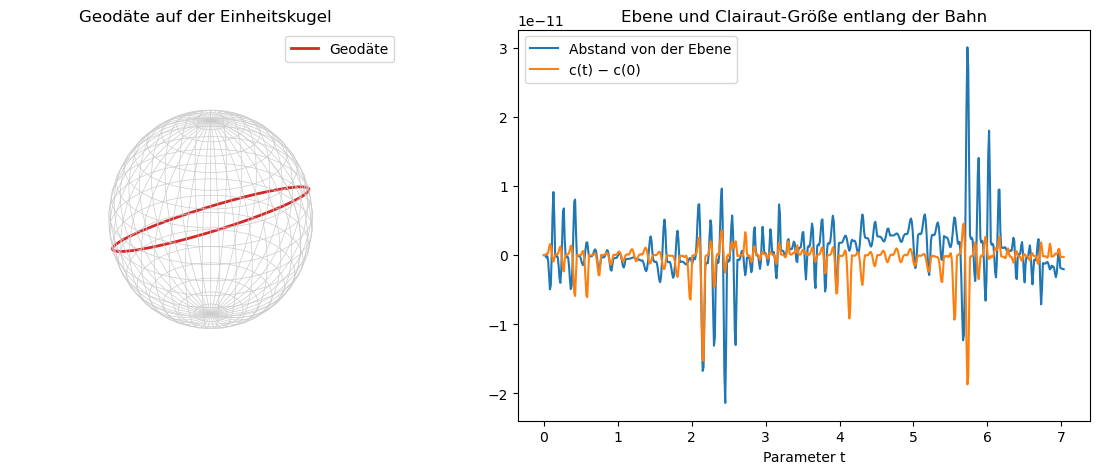

In [6]:
variations.sphere_geodesics()

**6. Differentialgleichungen: Werkzeuge**

Differentialgleichungen sagen nicht, wo etwas ist, sondern wie es sich ändert: Newtons Bewegungsgesetz, die Wellen- und die Wärmeleitungsgleichung, die Maxwell- und die Schrödinger-Gleichung. Nur wenige lassen sich geschlossen lösen, fast alle der Praxis löst man numerisch. Damit kommen eigene Fragen: Wie schnell fällt der Fehler mit der Schrittweite, bleibt die Energie erhalten, und wann wird ein Verfahren instabil?

Bereitgestellt werden die Schritte der Integratoren und ein Runge-Kutta-Schritt für viele Bahnen zugleich.

In [7]:
odes.load()

Werkzeuge bereit


**7. Exakte Lösungen mit sympy**

sympy löst den gedämpften Oszillator und die logistische Gleichung symbolisch und prüft die Lösungen durch Einsetzen.

Der Oszillator ergibt Exponentialfunktionen mit λ = −γ ± √(γ² − ω₀²); im aperiodischen Grenzfall fallen beide Exponenten zusammen, und ein Faktor t ersetzt die fehlende Lösung. Die logistische Gleichung ergibt eine S-Kurve von N₀ zur Kapazität K. Beide Lösungen bestehen die Probe.

In [8]:
odes.exact_solutions()

Gedämpfter Oszillator:


Eq(x(t), C1*exp(t*(-gamma + sqrt(gamma - omega_0)*sqrt(gamma + omega_0))) + C2*exp(-t*(gamma + sqrt(gamma - omega_0)*sqrt(gamma + omega_0))))

Aperiodischer Grenzfall γ = ω₀:


Eq(x(t), (C1 + C2*t)*exp(-omega_0*t))

Logistische Gleichung mit N(0) = N₀:


Eq(N(t), K*N_0*exp(r*t)/(K + N_0*exp(r*t) - N_0))

Probe durch Einsetzen (checkodesol): True True


**8. Lineare Systeme: Matrixexponential und Phasenporträts**

Die Lösung von dx/dt = A x ist e^(At) x₀. Vier Matrizen zeigen Knoten, Sattel, Spirale und Zentrum.

Beim Knoten läuft die Bahn ohne Drehung in den Ursprung, beim Sattel entlang der instabilen Richtung hinaus, bei der Spirale dreht sie sich nach innen, beim Zentrum läuft sie geschlossen. Spur und Determinante entscheiden: Der Sattel hat eine negative Determinante, Spirale und Zentrum komplexe Eigenwerte.

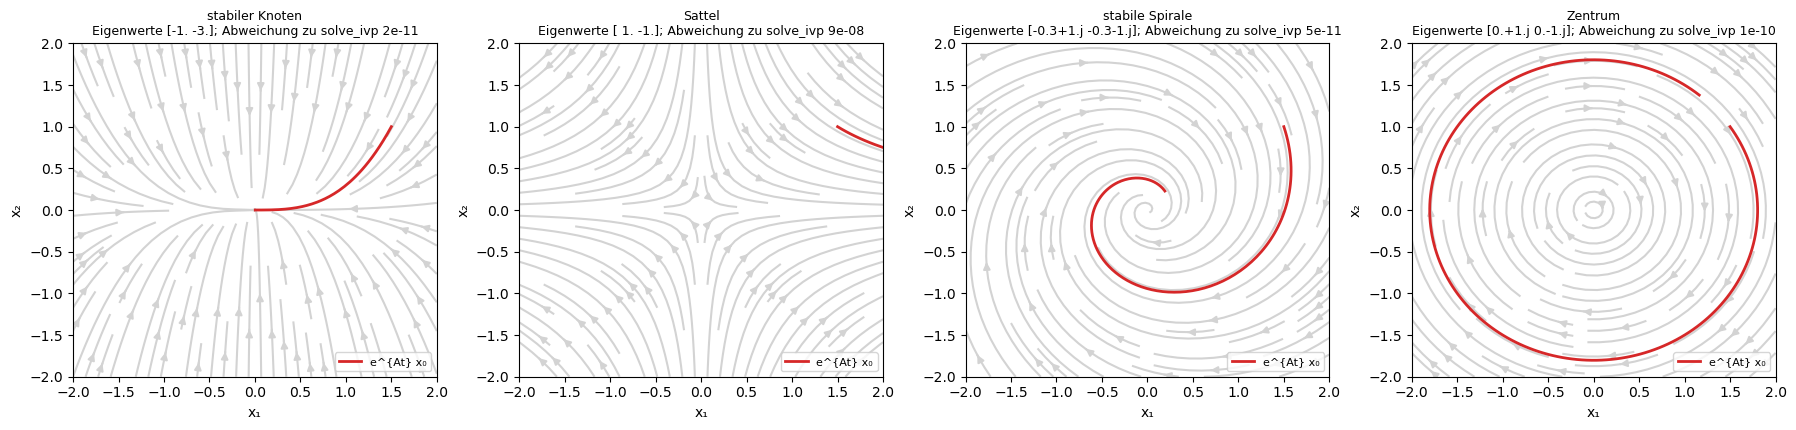

stabiler Knoten : Spur τ = -4.0, Determinante Δ = +3.00, τ² − 4Δ = +4.00
Sattel          : Spur τ = +0.0, Determinante Δ = -1.00, τ² − 4Δ = +4.00
stabile Spirale : Spur τ = -0.6, Determinante Δ = +1.09, τ² − 4Δ = -4.00
Zentrum         : Spur τ = +0.0, Determinante Δ = +1.00, τ² − 4Δ = -4.00


In [9]:
odes.linear_systems()

**9. Integratoren: Energie über lange Zeiten**

Der Oszillator ẍ = −x mit vier Verfahren: explizites Euler-Verfahren, symplektisches Euler-Verfahren, Störmer-Verlet und Runge-Kutta 4. Gemessen werden die Energie über lange Zeit und die Ordnung der Konvergenz.

Beim expliziten Euler-Verfahren wächst die Energie exponentiell, bis 10⁹. Die symplektischen Verfahren schwanken in einem festen Band ohne Drift. Runge-Kutta 4 ist viel genauer, driftet aber langsam, weil es nicht symplektisch ist. Die Ordnungen sind 1, 1, 2 und 4.

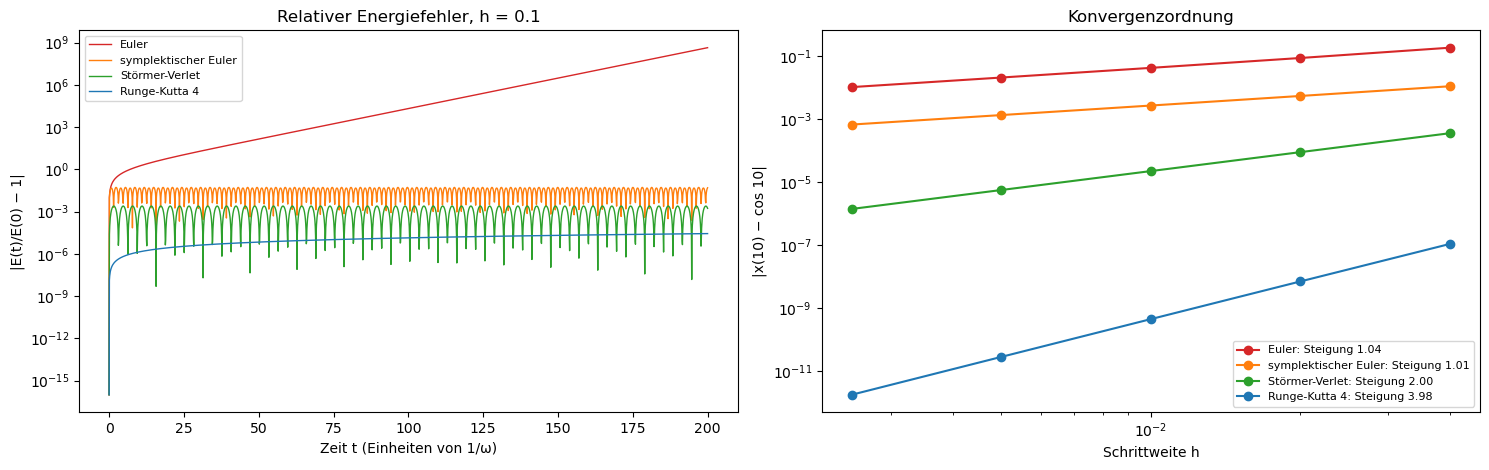

Euler                : Ordnung 1.04;  E(200)/E(0) = 4.393e+08
symplektischer Euler : Ordnung 1.01;  E(200)/E(0) = 1.05
Störmer-Verlet       : Ordnung 2.00;  E(200)/E(0) = 0.9983
Runge-Kutta 4        : Ordnung 3.98;  E(200)/E(0) = 1
Vorhersage für Euler: (1 + h²)^(T/h) = 4.393e+08


In [10]:
odes.integrators()

**10. Eine steife Gleichung**

Eine Gleichung mit einer sehr schnellen und einer langsamen Zeitskala. Explizite Verfahren müssen dem schnellen Teil folgen, auch wenn er längst abgeklungen ist.

Mit h = 0.0021 explodiert das explizite Verfahren, mit h = 0.0019 bleibt es stabil; die Grenze ist 2/1000. Das implizite Verfahren folgt mit zehnmal größerem Schritt sauber der Lösung. Bis t = 10 braucht das explizite RK45 21 548 Auswertungen, das implizite Radau nur 624, bei kleinerem Fehler.

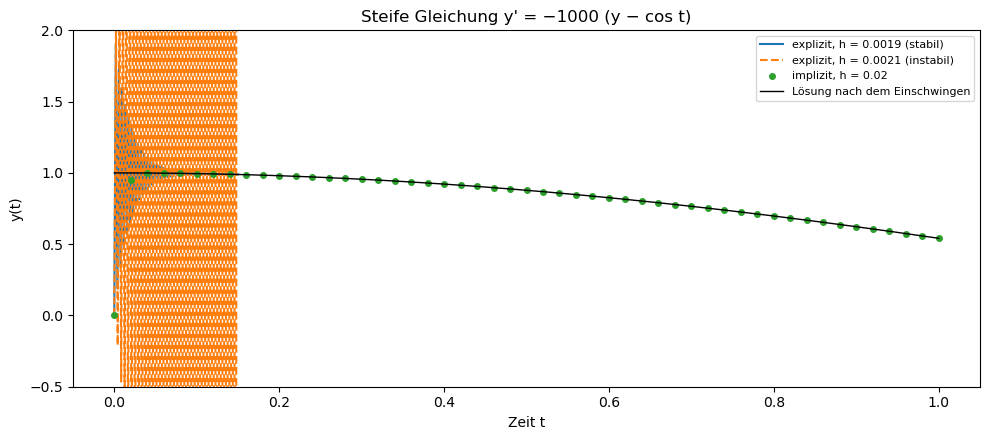

solve_ivp RK45 :  21548 Auswertungen der rechten Seite, Fehler am Ende 4.5e-07
solve_ivp Radau:    624 Auswertungen der rechten Seite, Fehler am Ende 2.1e-08


In [11]:
odes.stiff()

**11. Ein Eigenwertproblem: der Quantenoszillator**

Die zweite Ableitung wird auf einem Gitter durch Differenzen ersetzt; aus der Schrödinger-Gleichung wird eine tridiagonale Matrix, deren Eigenwerte die Energien sind.

Die Energien sind 0.5, 1.49998, 2.49996, …, wie n + ½. Die n-te Eigenfunktion hat n Nullstellen und reicht etwas über die klassischen Umkehrpunkte hinaus. Der Fehler fällt mit dem Quadrat der Gitterweite und wächst mit n, weil höhere Zustände stärker schwingen.

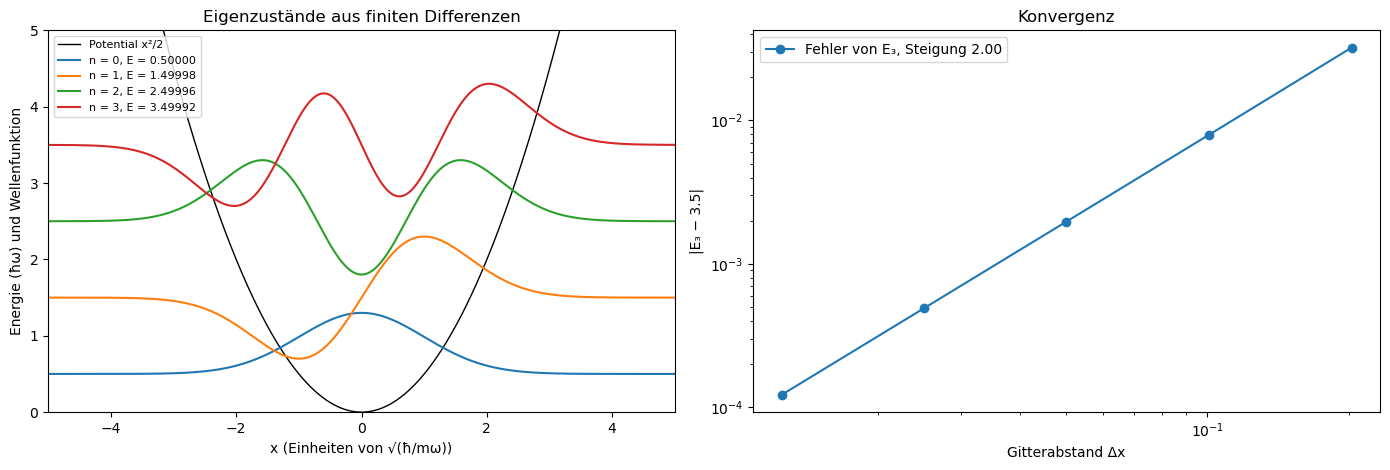

Niedrigste Energien: [0.5     1.49998 2.49996 3.49992 4.49987 5.49981] (exakt 0.5, 1.5, 2.5, …)
Fehler von E₃ fällt wie Δx^2.00


In [12]:
odes.eigenvalue_problem()

**12. Wärmeleitung: Fourier-Reihe gegen finite Differenzen**

Eine heiße Stufe in der Mitte eines Stabs mit kalten Enden, als Fourier-Reihe und mit dem expliziten Verfahren FTCS für drei Werte von r = αΔt/Δx².

Die Kanten runden sich sofort ab, dann sinkt die Mitte. Mit r = 0.4 stimmt FTCS auf 10⁻⁴ mit der Fourier-Reihe. Über r = ½ wird es instabil: Die kürzeste Gitterwelle wächst, bis sie das Bild sprengt.

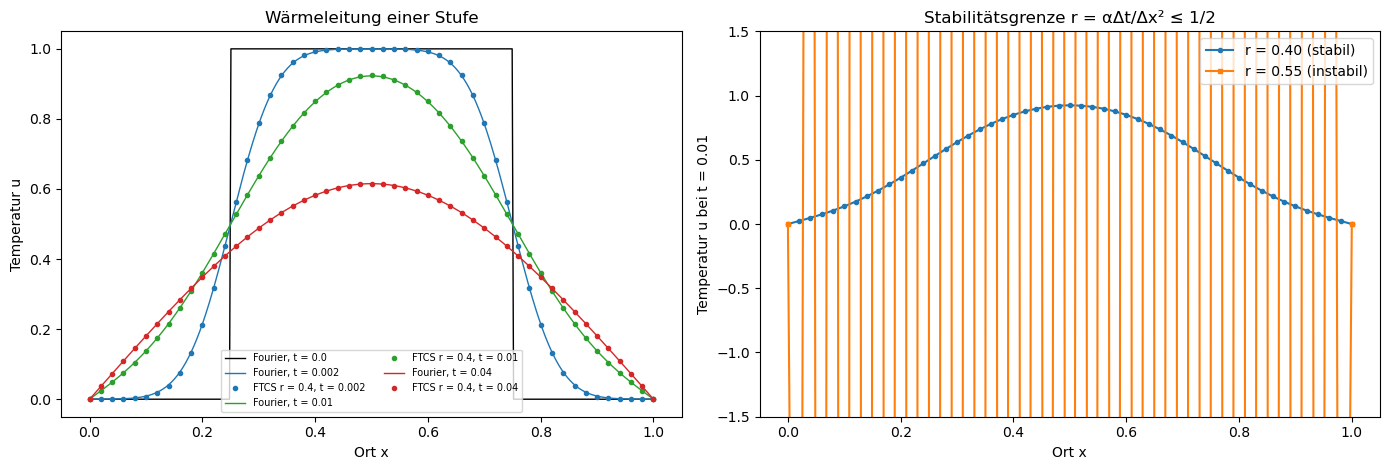

r = 0.4: größte Abweichung von der Fourier-Lösung bei t = 0.04: 1.2e-04
r = 0.5: größte Abweichung von der Fourier-Lösung bei t = 0.04: 1.8e-02
r = 0.55: größte Abweichung von der Fourier-Lösung bei t = 0.04: 4.9e+12


In [13]:
odes.heat()

**13. Die Wellengleichung und die CFL-Bedingung**

Eine gezupfte Saite, exakt als Fourier-Reihe und mit dem Leapfrog-Verfahren für drei Courant-Zahlen C = cΔt/Δx.

Das Dreieck teilt sich in zwei Hälften, die nach außen laufen, an den Enden umgekehrt zurückkommen und sich zum gespiegelten Dreieck formen. Mit C = 1 trifft Leapfrog die Lösung genau, mit C = 0.9 fast; mit C = 1.02 explodiert es. Die Information darf im Gitter nicht schneller laufen als die Welle (Courant, Friedrichs, Lewy).

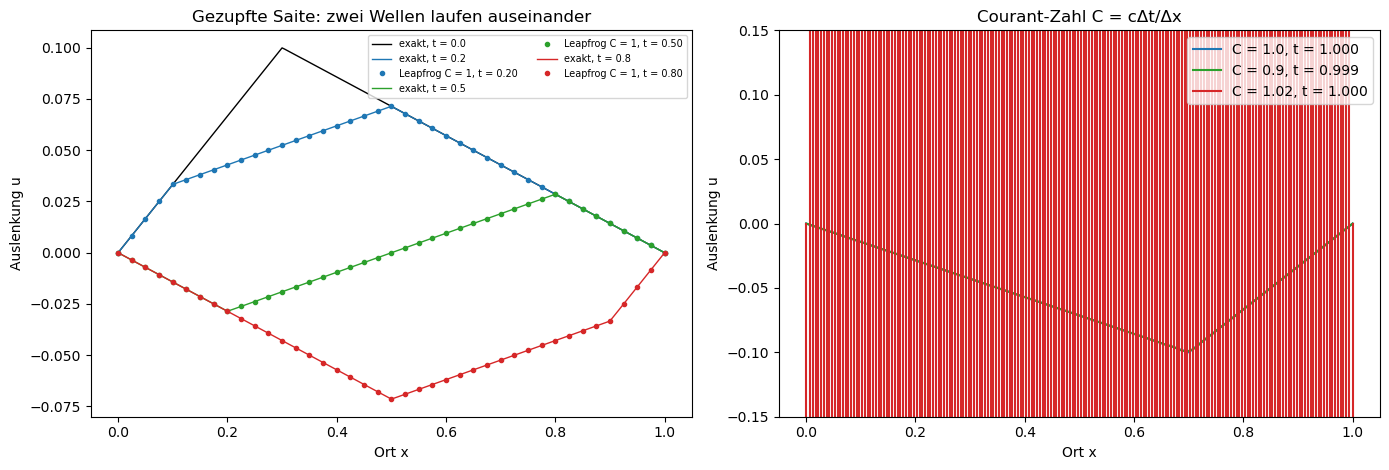

C = 1.0: größte Abweichung von der exakten Lösung bei t = 1.000: 8.0e-05
C = 0.9: größte Abweichung von der exakten Lösung bei t = 0.999: 8.8e-04
C = 1.02: größte Abweichung von der exakten Lösung bei t = 1.000: 5.2e+28


In [14]:
odes.wave_cfl()

**14. Die Schrödinger-Gleichung: Tunneln**

Ein Wellenpaket läuft auf eine Barriere zu, deren Höhe über seiner mittleren Energie liegt.

An der Barriere bilden einlaufende und reflektierte Welle dichte Interferenzstreifen. Der größte Teil wird reflektiert, ein kleiner Teil tunnelt durch (7 %). Die Transmission ebener Wellen steigt unterhalb der Barrierenhöhe steil an; das Paket liegt etwas darüber, weil es auch schnellere Anteile enthält.

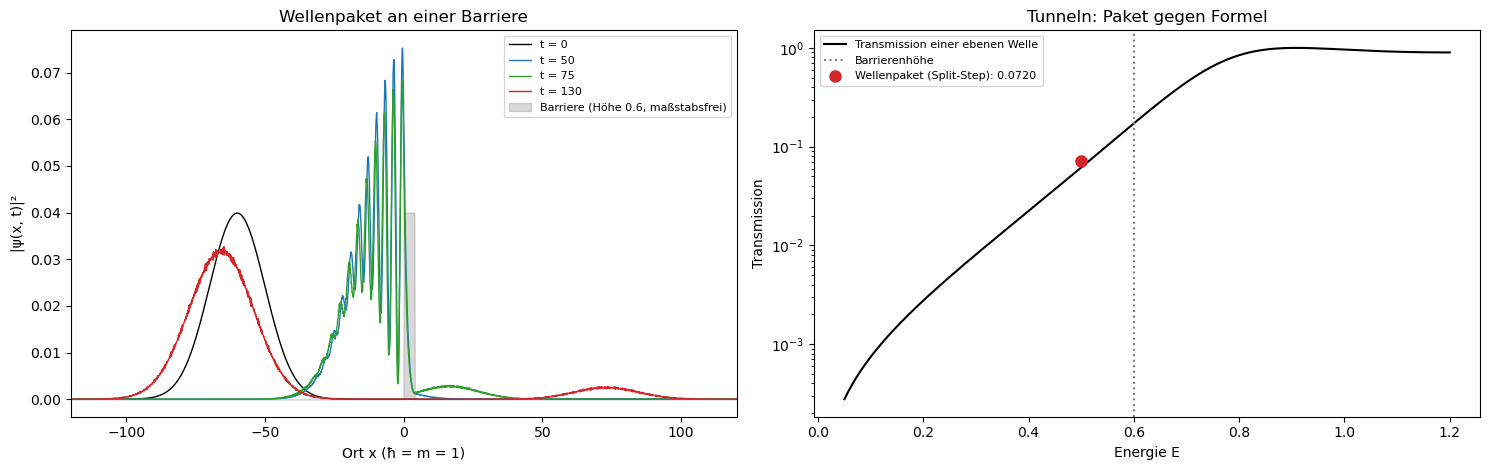

Transmittierter Anteil (Split-Step): 0.0720
Formel bei E = 0.5: 0.0617;  über die Impulsverteilung des Pakets gemittelt: 0.0716
Norm: größte Abweichung von 1 über 2601 Schritte: 1.4e-13


In [15]:
odes.schroedinger()

**15. Floquet-Theorie: die Stabilitätskarte der Mathieu-Gleichung**

Ein Oszillator, dessen Frequenz periodisch schwankt (Mathieu-Gleichung). Nach einer Periode multipliziert eine Matrix den Zustand; ihre Eigenwerte entscheiden, ob er wächst.

Instabile Zungen beginnen bei a = 0, 1, 4, 9, also a = n², und werden mit der Stärke q breiter; die bei a = 1 ist am stärksten, dort schwingt der Parameter mit der doppelten Eigenfrequenz (Schaukeln). Die Determinante der Matrix ist 1, wie Liouville verlangt.

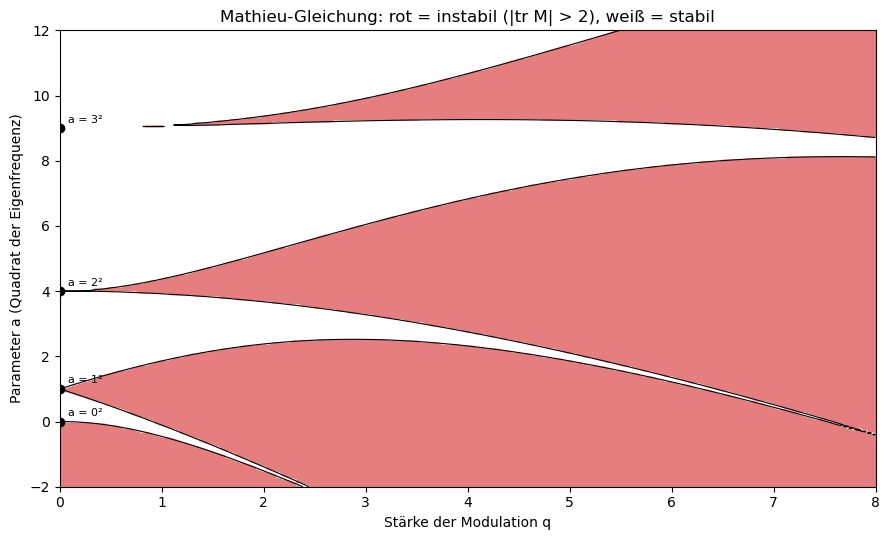

Determinante der Monodromiematrix: 0.9999999997 bis 1.0000000000 (Theorie 1)
Instabile Bereiche bei q = 2: a ∈ [-2.00, -1.55], a ∈ [-1.35, 2.35], a ∈ [3.70, 5.15], a ∈ [9.15, 9.35]


In [16]:
odes.floquet()

**16. Chaos: Werkzeuge**

Ein dynamisches System macht aus dem heutigen Zustand den von morgen: ein Pendel, das Wetter, eine Population. Ist die Regel deterministisch, legt der Anfang die ganze Zukunft fest. Lange nahm man an, dass man sie dann auch vorhersagen kann, wenn man den Anfang nur genau genug kennt. In chaotischen Systemen wächst aber jeder noch so kleine Fehler exponentiell, und nach endlicher Zeit ist die Vorhersage wertlos.

Bereitgestellt werden ein Runge-Kutta-Schritt, die logistische Abbildung, das Lorenz-System mit seiner Jacobi-Matrix und das Zählen von Kästchen für die fraktale Dimension.

In [17]:
nonlinear.load()

Funktionen bereit


**17. Phasenraum des Pendels**

Ohne Dämpfung sind die Bahnen die Höhenlinien der Energie, mit Dämpfung fällt die Energie entlang jeder Bahn: Sie ist eine Lyapunov-Funktion, die Stabilität beweist.

Um die Ruhelage liegen geschlossene Bahnen (Schwingen), darüber offene (Überschlagen); die Separatrix durch die Sattelpunkte trennt beide. Mit Dämpfung spiralen alle Bahnen in die Ruhelage, und die Energie fällt monoton; die Bahn, die fast auf dem Kopf startet, verharrt erst lange oben.

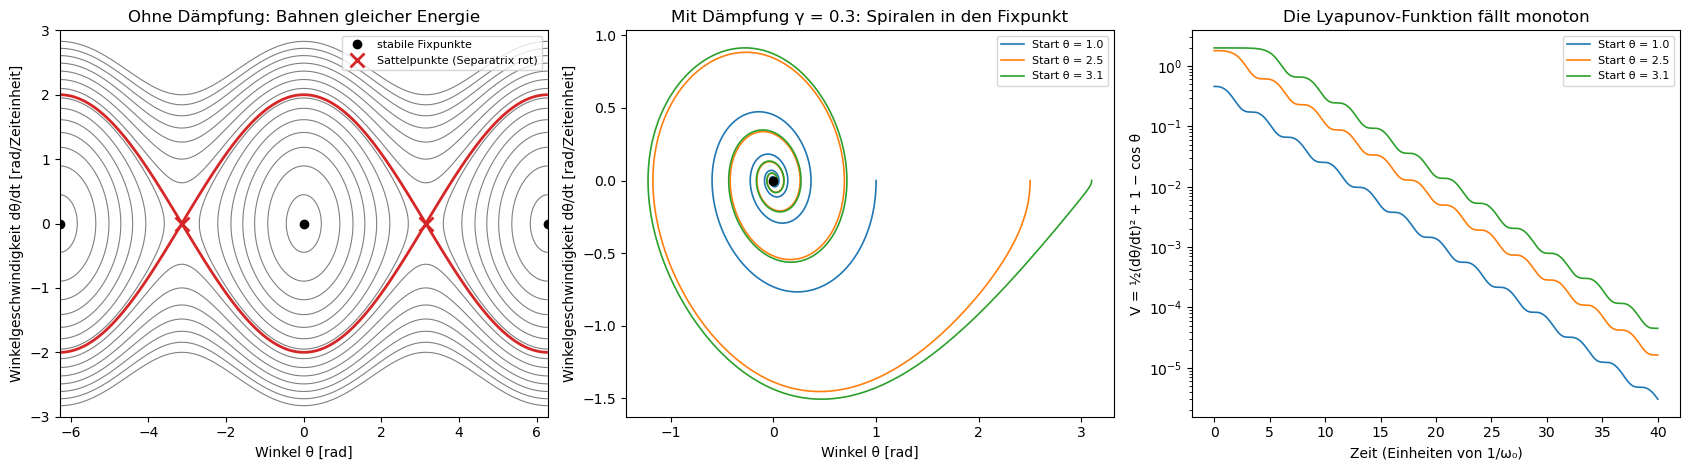

Eigenwerte am Fixpunkt θ = 0: [-0.15+0.989j -0.15-0.989j]  (komplex, Realteil < 0: stabile Spirale)
Eigenwerte am Fixpunkt θ = π: [ 0.861 -1.161]  (reell, verschiedene Vorzeichen: Sattel)
Größte Zunahme von V zwischen zwei Zeitpunkten: -1.2e-11 (≤ 0 bis auf Rundung)


In [18]:
nonlinear.pendulum()

**18. Die logistische Abbildung**

x ↦ r x (1 − x), die einfachste Gleichung mit Chaos. Das Bifurkationsdiagramm zeigt die Langzeitwerte für jedes r, der Lyapunov-Exponent misst, wie schnell kleine Abweichungen wachsen.

Bei r = 3 spaltet sich der Fixpunkt in einen 2-Zyklus, bei 3.449 in einen 4-Zyklus, und die Verdopplungen folgen immer schneller aufeinander, mit dem Verhältnis der Feigenbaum-Konstante 4.669. Ab 3.57 herrscht Chaos mit positivem Lyapunov-Exponenten, unterbrochen von periodischen Fenstern wie dem 3-Zyklus bei 3.83.

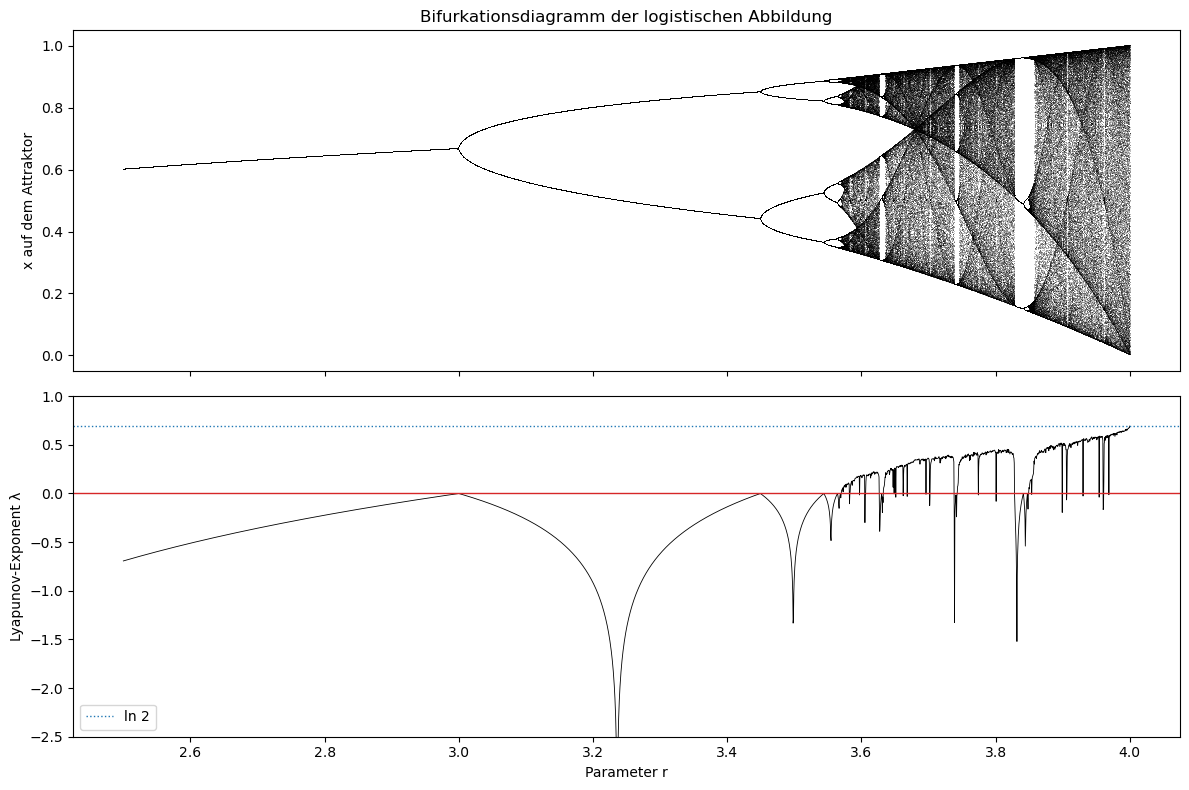

Superstabile Parameter R_n: 2.000000, 3.236068, 3.498562, 3.554641, 3.566667, 3.569244, 3.569795, 3.569913, 3.569939
Verhältnisse (R_n − R_(n−1)) / (R_(n+1) − R_n): 4.7089, 4.6808, 4.6630, 4.6684, 4.6690, 4.6692, 4.6692
Lyapunov-Exponent bei r = 4: 0.6929   (ln 2 = 0.6931)
Erstes r mit λ > 0 (Beginn des Chaos, Gitterauflösung 0.0005): 3.5704


In [19]:
nonlinear.logistic_map()

**19. Der Schmetterlingseffekt im Lorenz-System**

Lorenz fand 1963 in einem vereinfachten Modell der Konvektion, dass zwei fast gleiche Anfänge auseinanderlaufen. Zwei Bahnen starten 10⁻⁹ voneinander entfernt.

Der Attraktor hat zwei Flügel, zwischen denen die Bahn unregelmäßig wechselt. Der Abstand der beiden Bahnen wächst im Mittel exponentiell mit der Rate 0.82 und erreicht nach etwa 25 Zeiteinheiten die Größe des Attraktors; danach sind die Bahnen unabhängig.

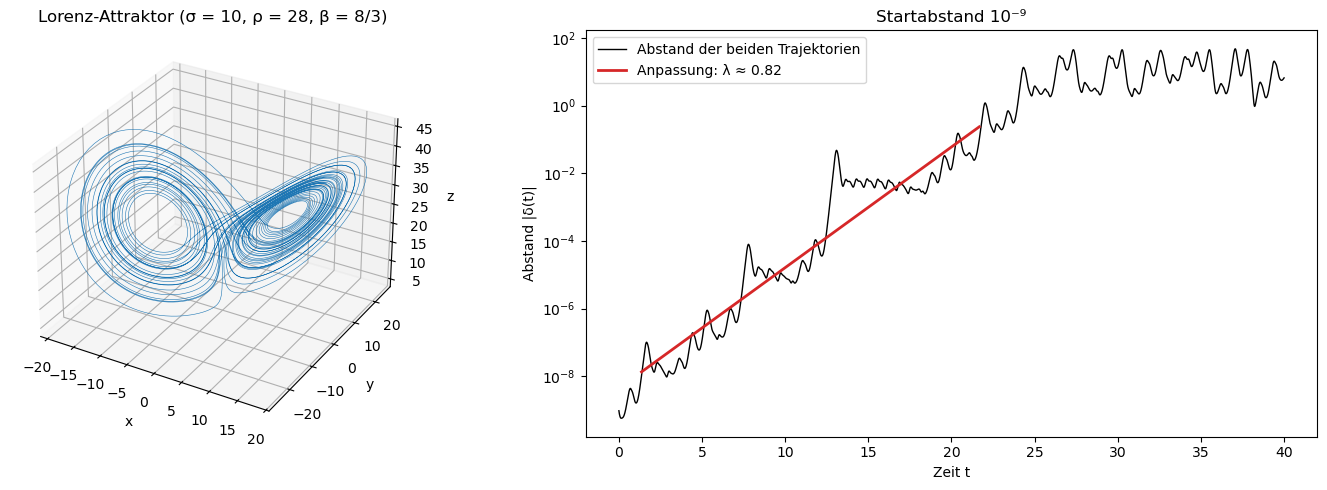

Wachstumsrate aus der Anpassung: 0.821;  Vorhersagehorizont von 10⁻⁹ bis 1: ln(10⁹)/λ ≈ 25 Zeiteinheiten


In [20]:
nonlinear.lorenz_system()

**20. Das Spektrum der Lyapunov-Exponenten**

Mit dem Verfahren von Benettin werden die Bahn und drei Störungen gemeinsam integriert und immer wieder orthonormiert; ihre mittleren Wachstumsraten sind die drei Lyapunov-Exponenten.

Sie konvergieren gegen 0.899, 0.000 und −14.566. Ihre Summe ist −13.667, genau die Divergenz des Systems: Volumen schrumpfen. Der mittlere Exponent ist null, weil eine Störung entlang der Bahn nur eine Zeitverschiebung ist. Aus dem Spektrum folgt die Dimension des Attraktors, etwas über 2.

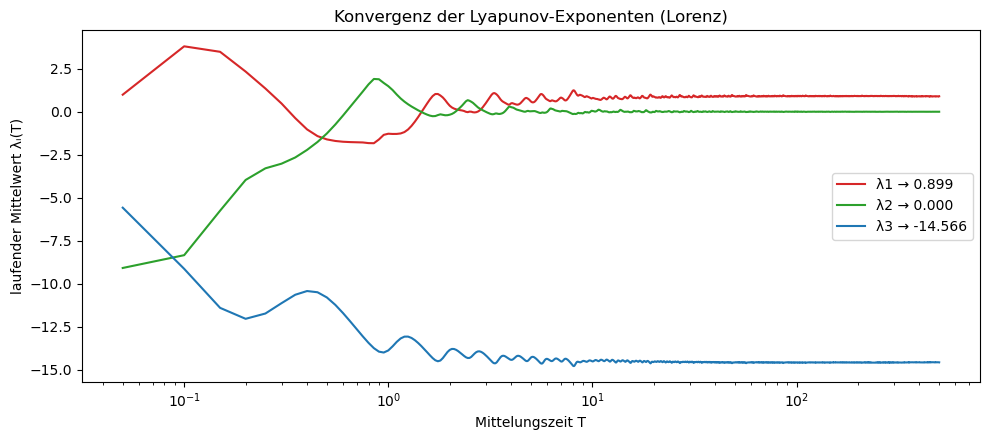

Lyapunov-Spektrum: λ1 = 0.899, λ2 = 0.000, λ3 = -14.566
Summe: -13.667   (Divergenz −σ − 1 − β = -13.667)
Kaplan-Yorke-Dimension: D = 2 + 0.899/14.566 = 2.062


In [21]:
nonlinear.lyapunov_spectrum()

**21. Fraktale Dimension**

Die Box-Counting-Dimension zählt, wie viele Kästchen der Größe ε eine Menge bedeckt. Beispiele: die Kochkurve und der Hénon-Attraktor.

Die Kochkurve hat 1.258 (exakt ln 4/ln 3 = 1.262), der Hénon-Attraktor 1.228; beide liegen zwischen 1 und 2, mehr als eine Kurve und weniger als eine Fläche. Der Hénon-Attraktor besteht aus vielen dünnen Schichten, die sich bei jedem Schritt strecken und falten.

Kochkurve: N(ε) = [19, 75, 303, 1212, 4726]


Hénon: N(ε) = [7546, 4084, 2183, 1163, 627, 326, 171, 94, 50, 27]


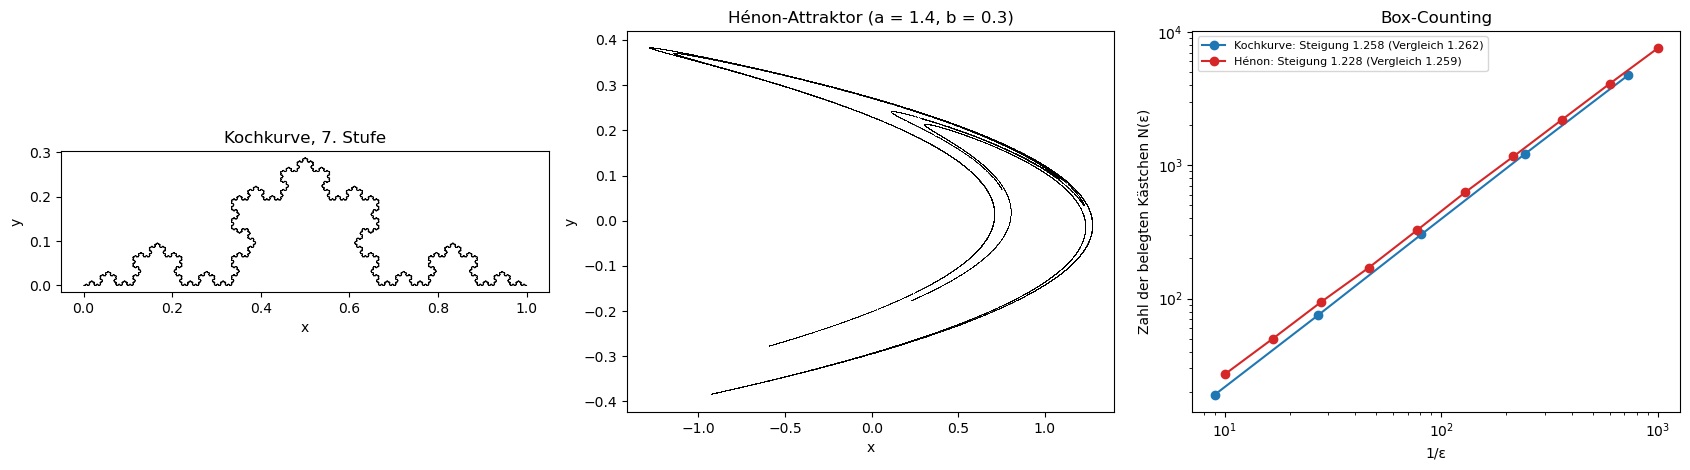

Kochkurve: Box-Counting 1.258, exakt ln4/ln3 = 1.2619
Hénon: λ1 = 0.420, λ2 = -1.624 (Summe -1.204, ln 0.3 = -1.204); Kaplan-Yorke 1.259, Box-Counting 1.228


In [22]:
nonlinear.fractal_dimension()